In [1]:
import pandas as pd

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

X_train, y_train = train.drop(columns="Churn"), train["Churn"]
X_test, y_test = test.drop(columns="Churn"), test["Churn"]

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5625, 23) | Test: (1407, 23)


normalization

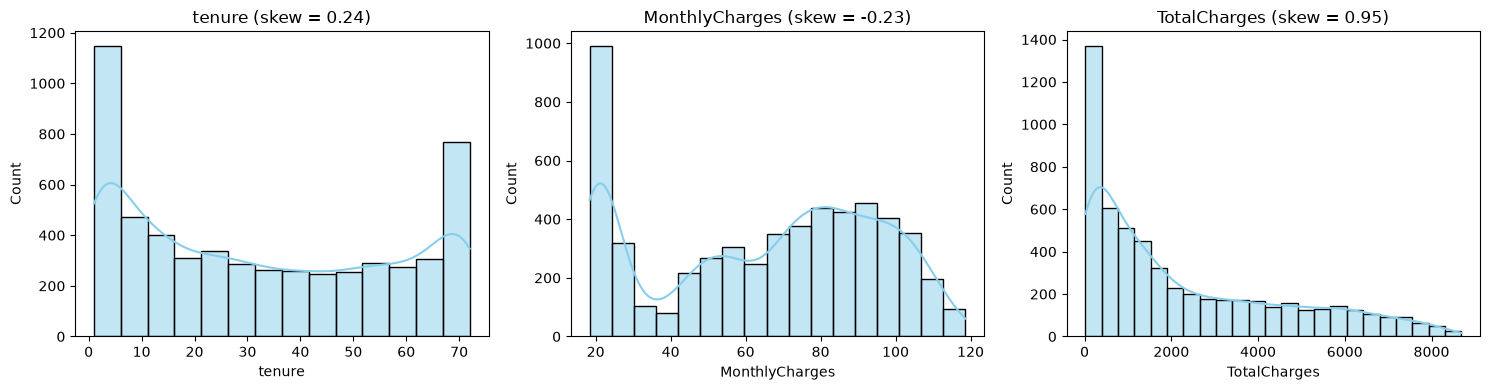

tenure            0.237
MonthlyCharges   -0.230
TotalCharges      0.954
dtype: float64


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    sns.histplot(X_train[col], kde=True, ax=ax, color="skyblue")
    ax.set_title(f"{col} (skew = {X_train[col].skew():.2f})")

plt.tight_layout()
plt.show()

# Skewness values as a table
print(X_train[num_cols].skew().round(3))

In [3]:
import numpy as np
import joblib
import os
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Work on copies so the unscaled data stays available
X_train_s = X_train.copy()
X_test_s = X_test.copy()

# Step 1: log transform to reduce the skew in TotalCharges
X_train_s["TotalCharges"] = np.log1p(X_train_s["TotalCharges"])
X_test_s["TotalCharges"] = np.log1p(X_test_s["TotalCharges"])

# Step 2: StandardScaler, fitted on TRAIN only
scaler = StandardScaler()
X_train_s[num_cols] = scaler.fit_transform(X_train_s[num_cols])
X_test_s[num_cols] = scaler.transform(X_test_s[num_cols])   # transform only, no fit

# Verify: train means should be about 0 and stds about 1
print(X_train_s[num_cols].describe().loc[["mean", "std", "min", "max"]].round(3))
print("\nTotalCharges skew after log:", round(X_train_s["TotalCharges"].skew(), 3))

# Save the scaler for the API later
os.makedirs("../models", exist_ok=True)
joblib.dump(scaler, "../models/scaler.pkl")

      tenure  MonthlyCharges  TotalCharges
mean  -0.000           0.000         0.000
std    1.000           1.000         1.000
min   -1.286          -1.548        -2.575
max    1.607           1.782         1.370

TotalCharges skew after log: -0.754


['../models/scaler.pkl']

model architecture 

In [5]:
# pip install tensorflow   (run once in a terminal if you get an import error)
import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(42)

input_dim = X_train_s.shape[1]
print("Input features:", input_dim)

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(64, activation="relu"),
    # layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    # layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")   # outputs churn probability (0 to 1)
])

model.summary()

Input features: 23


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,177 (71.00 KB)

 Trainable params: 18,177 (71.00 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# Hold out a validation set from the training data (test set stays untouched)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_s, y_train, test_size=0.15, stratify=y_train, random_state=42
)

# Class weights to handle imbalance (~26% churn)
n_neg, n_pos = (y_tr == 0).sum(), (y_tr == 1).sum()
class_weight = {0: 1.0, 1: n_neg / n_pos}
print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

# Compile: loss + optimizer + metrics
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.AUC(name="auc")]
)

# Early stopping: stop when validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,                 # wait 10 epochs for improvement
    restore_best_weights=True    # roll back to the best epoch
)



Class weights: {0: 1.0, 1: np.float64(2.76)}


In [7]:
# Train
history = model.fit(
    X_tr.values.astype("float32"), y_tr.values,
    validation_data=(X_val.values.astype("float32"), y_val.values),
    epochs=100,
    batch_size=64,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=1
)

print("Stopped at epoch:", len(history.history["loss"]))

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7379 - auc: 0.8138 - loss: 0.7799 - recall: 0.7388 - val_accuracy: 0.7618 - val_auc: 0.8372 - val_loss: 0.4656 - val_recall: 0.7188
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7611 - auc: 0.8503 - loss: 0.7040 - recall: 0.7994 - val_accuracy: 0.7500 - val_auc: 0.8375 - val_loss: 0.4663 - val_recall: 0.7009
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7651 - auc: 0.8562 - loss: 0.6910 - recall: 0.8057 - val_accuracy: 0.7488 - val_auc: 0.8367 - val_loss: 0.4640 - val_recall: 0.7054
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7636 - auc: 0.8599 - loss: 0.6825 - recall: 0.8049 - val_accuracy: 0.7464 - val_auc: 0.8359 - val_loss: 0.4635 - val_recall: 0.7009
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7664 - auc: 0.8635 - loss: 0.6740 - recall: 0.8088 - val_accuracy: 0.7488 - val_auc: 0.8343 - val_loss: 0.4648 - val_recall: 0.6964
Epoch 6/100
75

In [8]:
early_stop = EarlyStopping(monitor="val_auc", mode="max", patience=10, restore_best_weights=True)

In [9]:
import os

os.makedirs("../models", exist_ok=True)
model.save("../models/churn_ann.keras")

print(os.listdir("../models"))

['churn_ann.keras', 'scaler.pkl']


44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Test ROC-AUC: 0.8427

               precision    recall  f1-score   support

    No churn       0.90      0.77      0.83      1033
       Churn       0.55      0.78      0.65       374

    accuracy                           0.77      1407
   macro avg       0.73      0.77      0.74      1407
weighted avg       0.81      0.77      0.78      1407



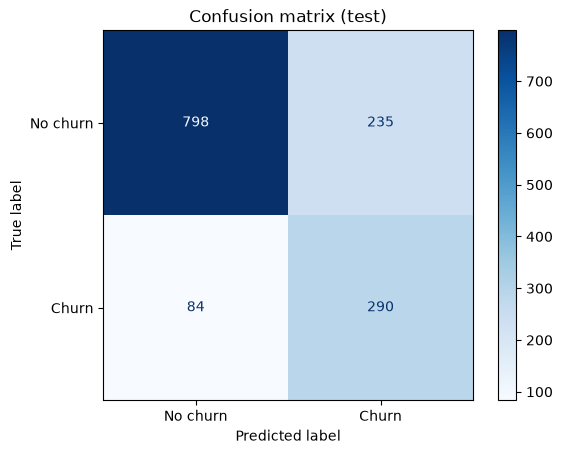

In [10]:
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Reload from disk to confirm the saved file works
saved_model = load_model("../models/churn_ann.keras")

# Predict churn probabilities, then apply the 0.5 threshold
y_prob = saved_model.predict(X_test_s.values.astype("float32")).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\n", classification_report(y_test, y_pred, target_names=["No churn", "Churn"]))

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title("Confusion matrix (test)")
plt.show()